In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.model_selection import cross_validate, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from scipy import stats
from scipy.stats import mannwhitneyu
from scipy.stats import f_oneway, kruskal

In [2]:
url_gasto_energetico = "../data/processed/gasto_energetico_hogar2.csv"

df_gasto_energetico = pd.read_csv(url_gasto_energetico)

print(df_gasto_energetico.info())


<class 'pandas.DataFrame'>
RangeIndex: 19544 entries, 0 to 19543
Data columns (total 87 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GASTO_SUMINISTROS  19544 non-null  float64
 1   CCAA               19544 non-null  str    
 2   NUTS1              19544 non-null  str    
 3   CAPROV             19544 non-null  str    
 4   TAMAMU             19544 non-null  str    
 5   DENSIDAD           19544 non-null  str    
 6   NMIEMB             19544 non-null  int64  
 7   NMIEM1             19544 non-null  int64  
 8   NMIEM2             19544 non-null  int64  
 9   NMIEM3             19544 non-null  int64  
 10  NMIEM4             19544 non-null  int64  
 11  NMIEM5             19544 non-null  int64  
 12  NMIEM6             19544 non-null  int64  
 13  NMIEM7             19544 non-null  int64  
 14  NMIEM8             19544 non-null  int64  
 15  NMIEM9             19544 non-null  int64  
 16  NMIEM10            19544 non-null

In [3]:
no_num = df_gasto_energetico.select_dtypes(exclude="number").columns.tolist()

no_num_binary = [
    col for col in no_num
    if df_gasto_energetico[col].nunique(dropna=False) == 2
]

bin_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(
        drop="if_binary",        # deja 1 columna binaria (0.0 / 1.0) por variable
        handle_unknown="ignore", # evita fallos si aparece un valor inesperado en test_set
        sparse_output=False,     # devuelve array denso de numpy en vez de matriz dispersa
    )),
])

X_train_bin = bin_pipeline.fit_transform(df_gasto_energetico[no_num_binary])

cols_bin_out = bin_pipeline.get_feature_names_out(no_num_binary)
df_train_bin = pd.DataFrame(X_train_bin, columns=cols_bin_out, index=df_gasto_energetico.index)

#print(df_train_bin.head().to_string())
df_gasto_energetico_with_bin = df_gasto_energetico.drop(columns=no_num_binary).copy()
df_gasto_energetico_with_bin = pd.concat([df_gasto_energetico_with_bin, df_train_bin], axis=1)
df_gasto_energetico_with_bin.head()

,GASTO_SUMINISTROS,CCAA,NUTS1,TAMAMU,DENSIDAD,NMIEMB,NMIEM1,NMIEM2,NMIEM3,NMIEM4,...,DISPOSIOV_Sí,CAPROP_Si,CAJENA_Si,PENSIOJUB_Si,PENSIOINCAP_Si,PENSIOTR_Si,DESEM_Si,OTRSUB_Si,RENTAS_Si,OTROIN_Si
0,760.428414,Cataluña,Este,Municipio con 10.000 o más y menos de 20.000 h...,Zona intermedia,4,3,1,2,2,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1030.630587,Comunitat Valenciana,Este,Municipio de 100.000 habitantes o más,Zona densamente poblada,2,2,0,0,2,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1265.599996,Galicia,Noroeste,Municipio de 100.000 habitantes o más,Zona densamente poblada,2,2,0,0,2,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1068.580361,Cataluña,Este,Municipio de 100.000 habitantes o más,Zona densamente poblada,4,2,2,2,2,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,880.480000,"Navarra, Comunidad Foral de",Noreste,Municipio con menos de 10.000 habitantes,Zona diseminada,2,2,0,0,2,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


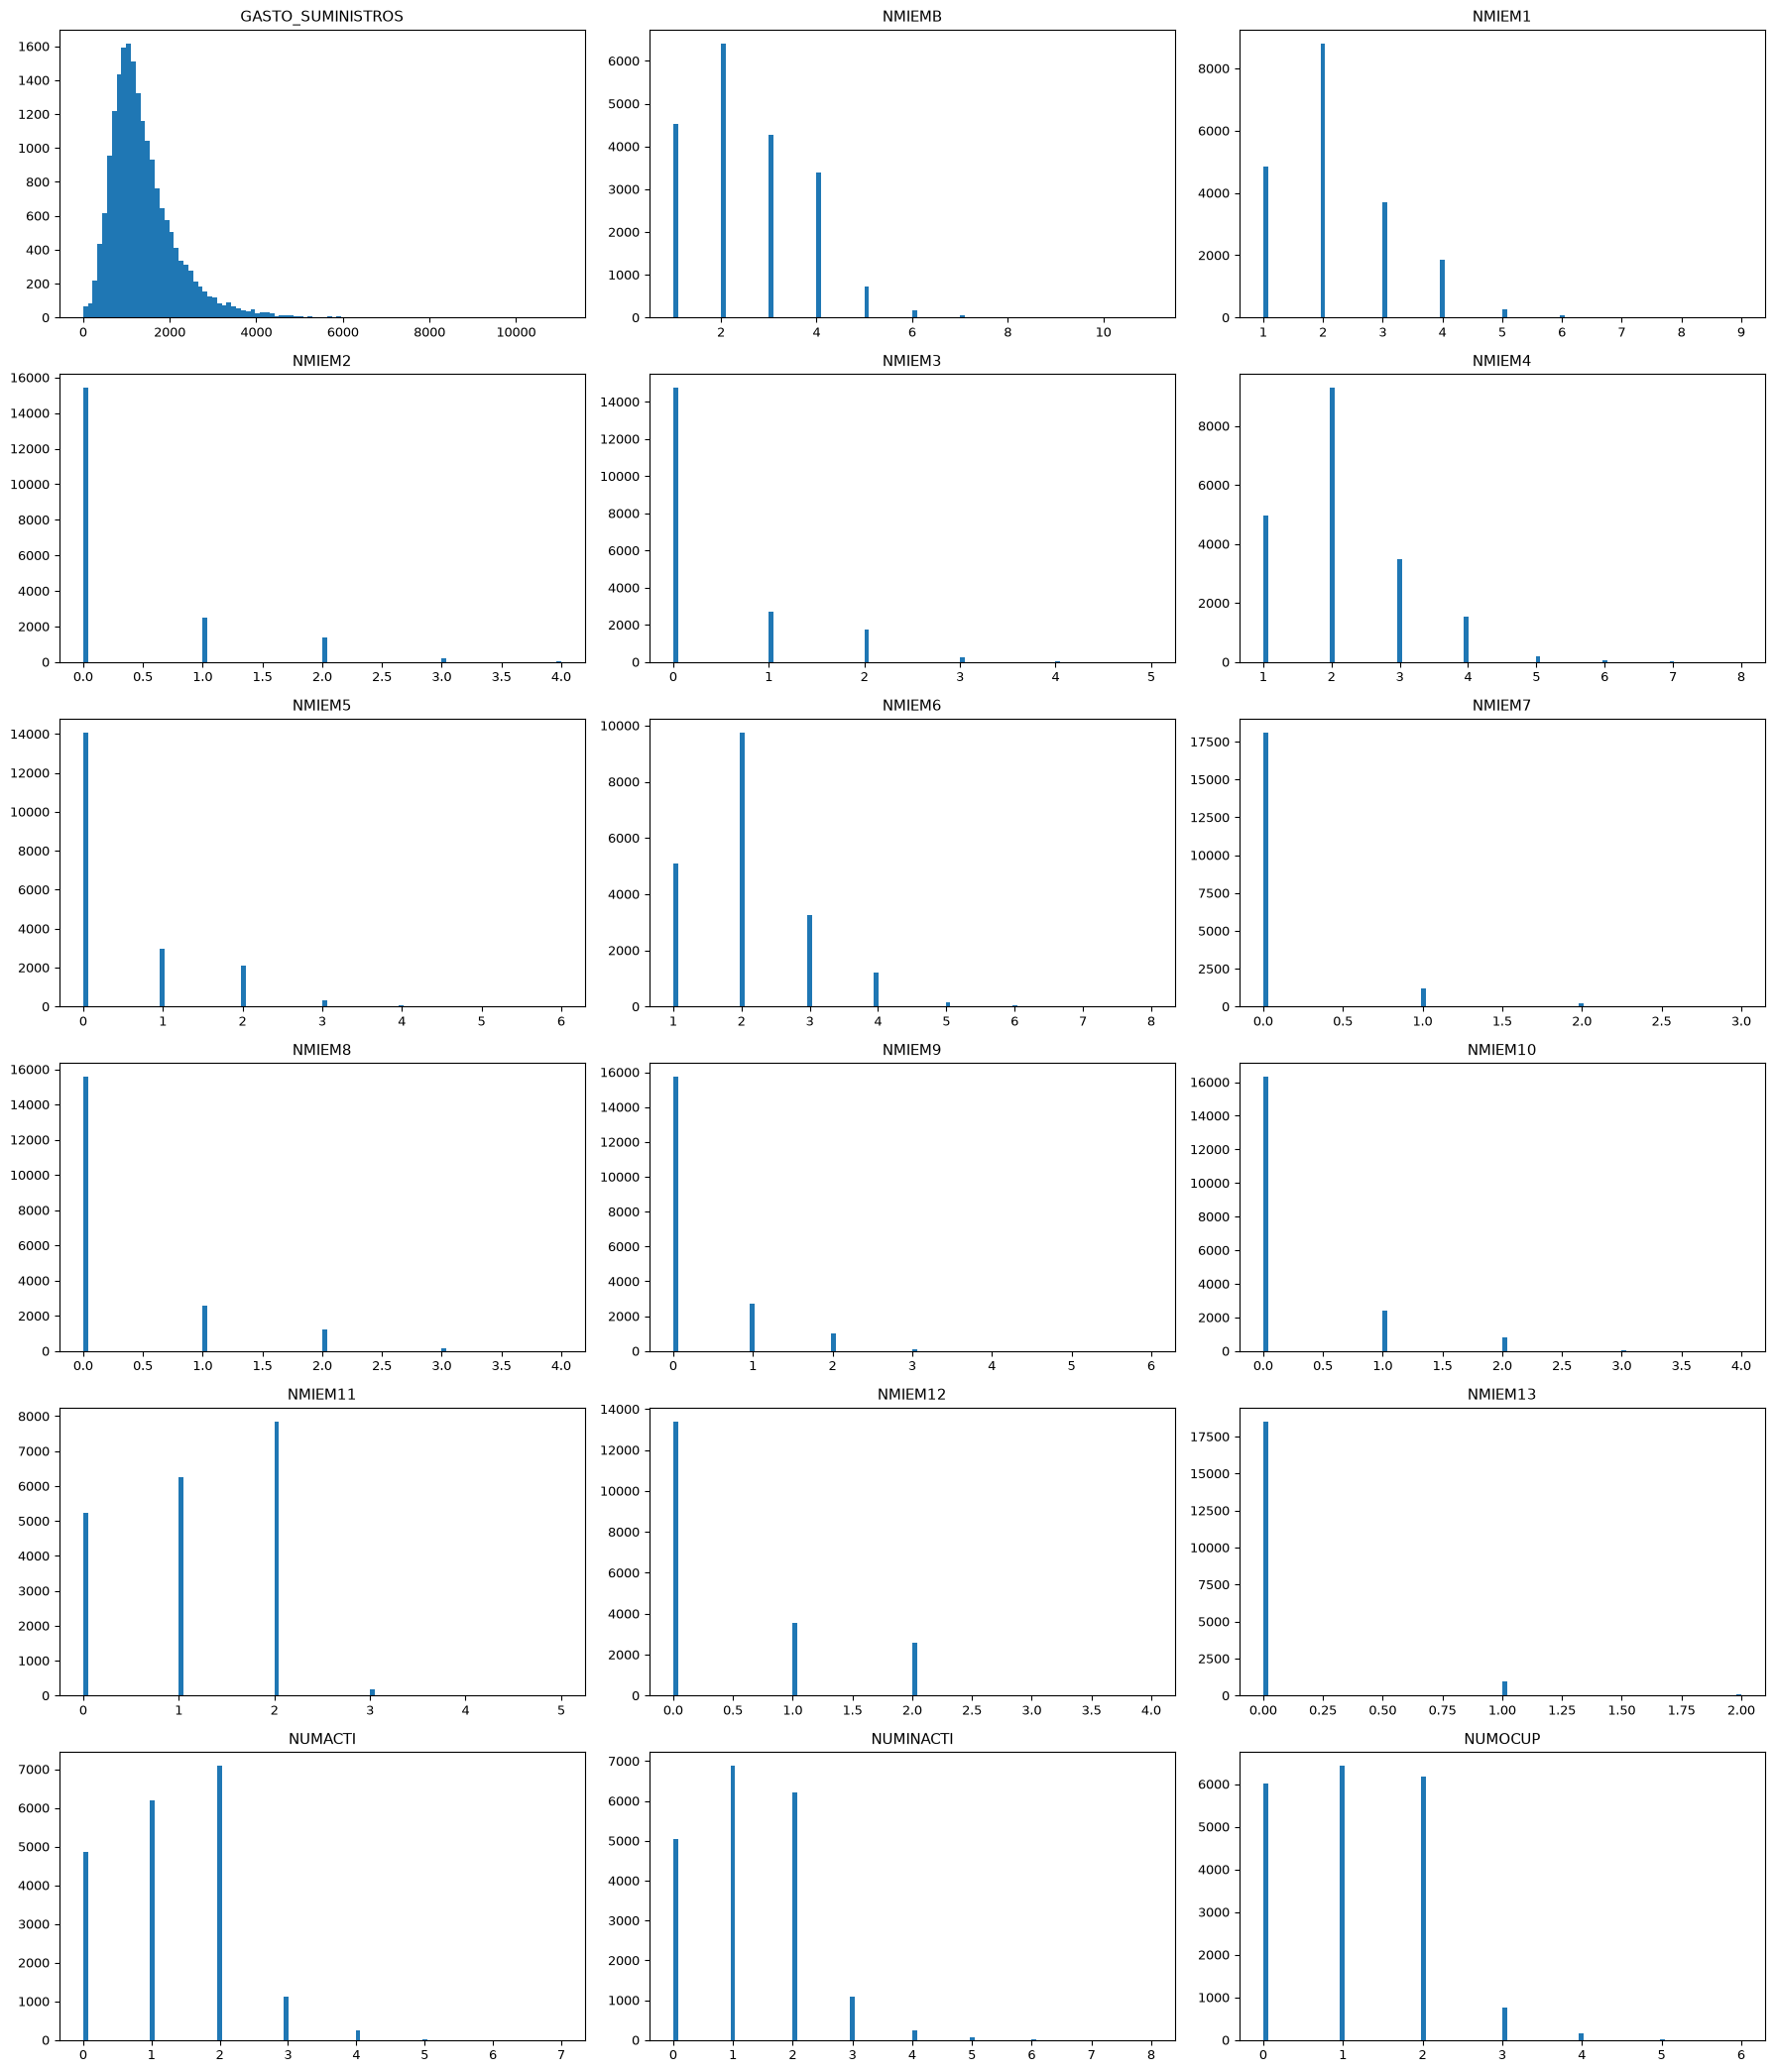

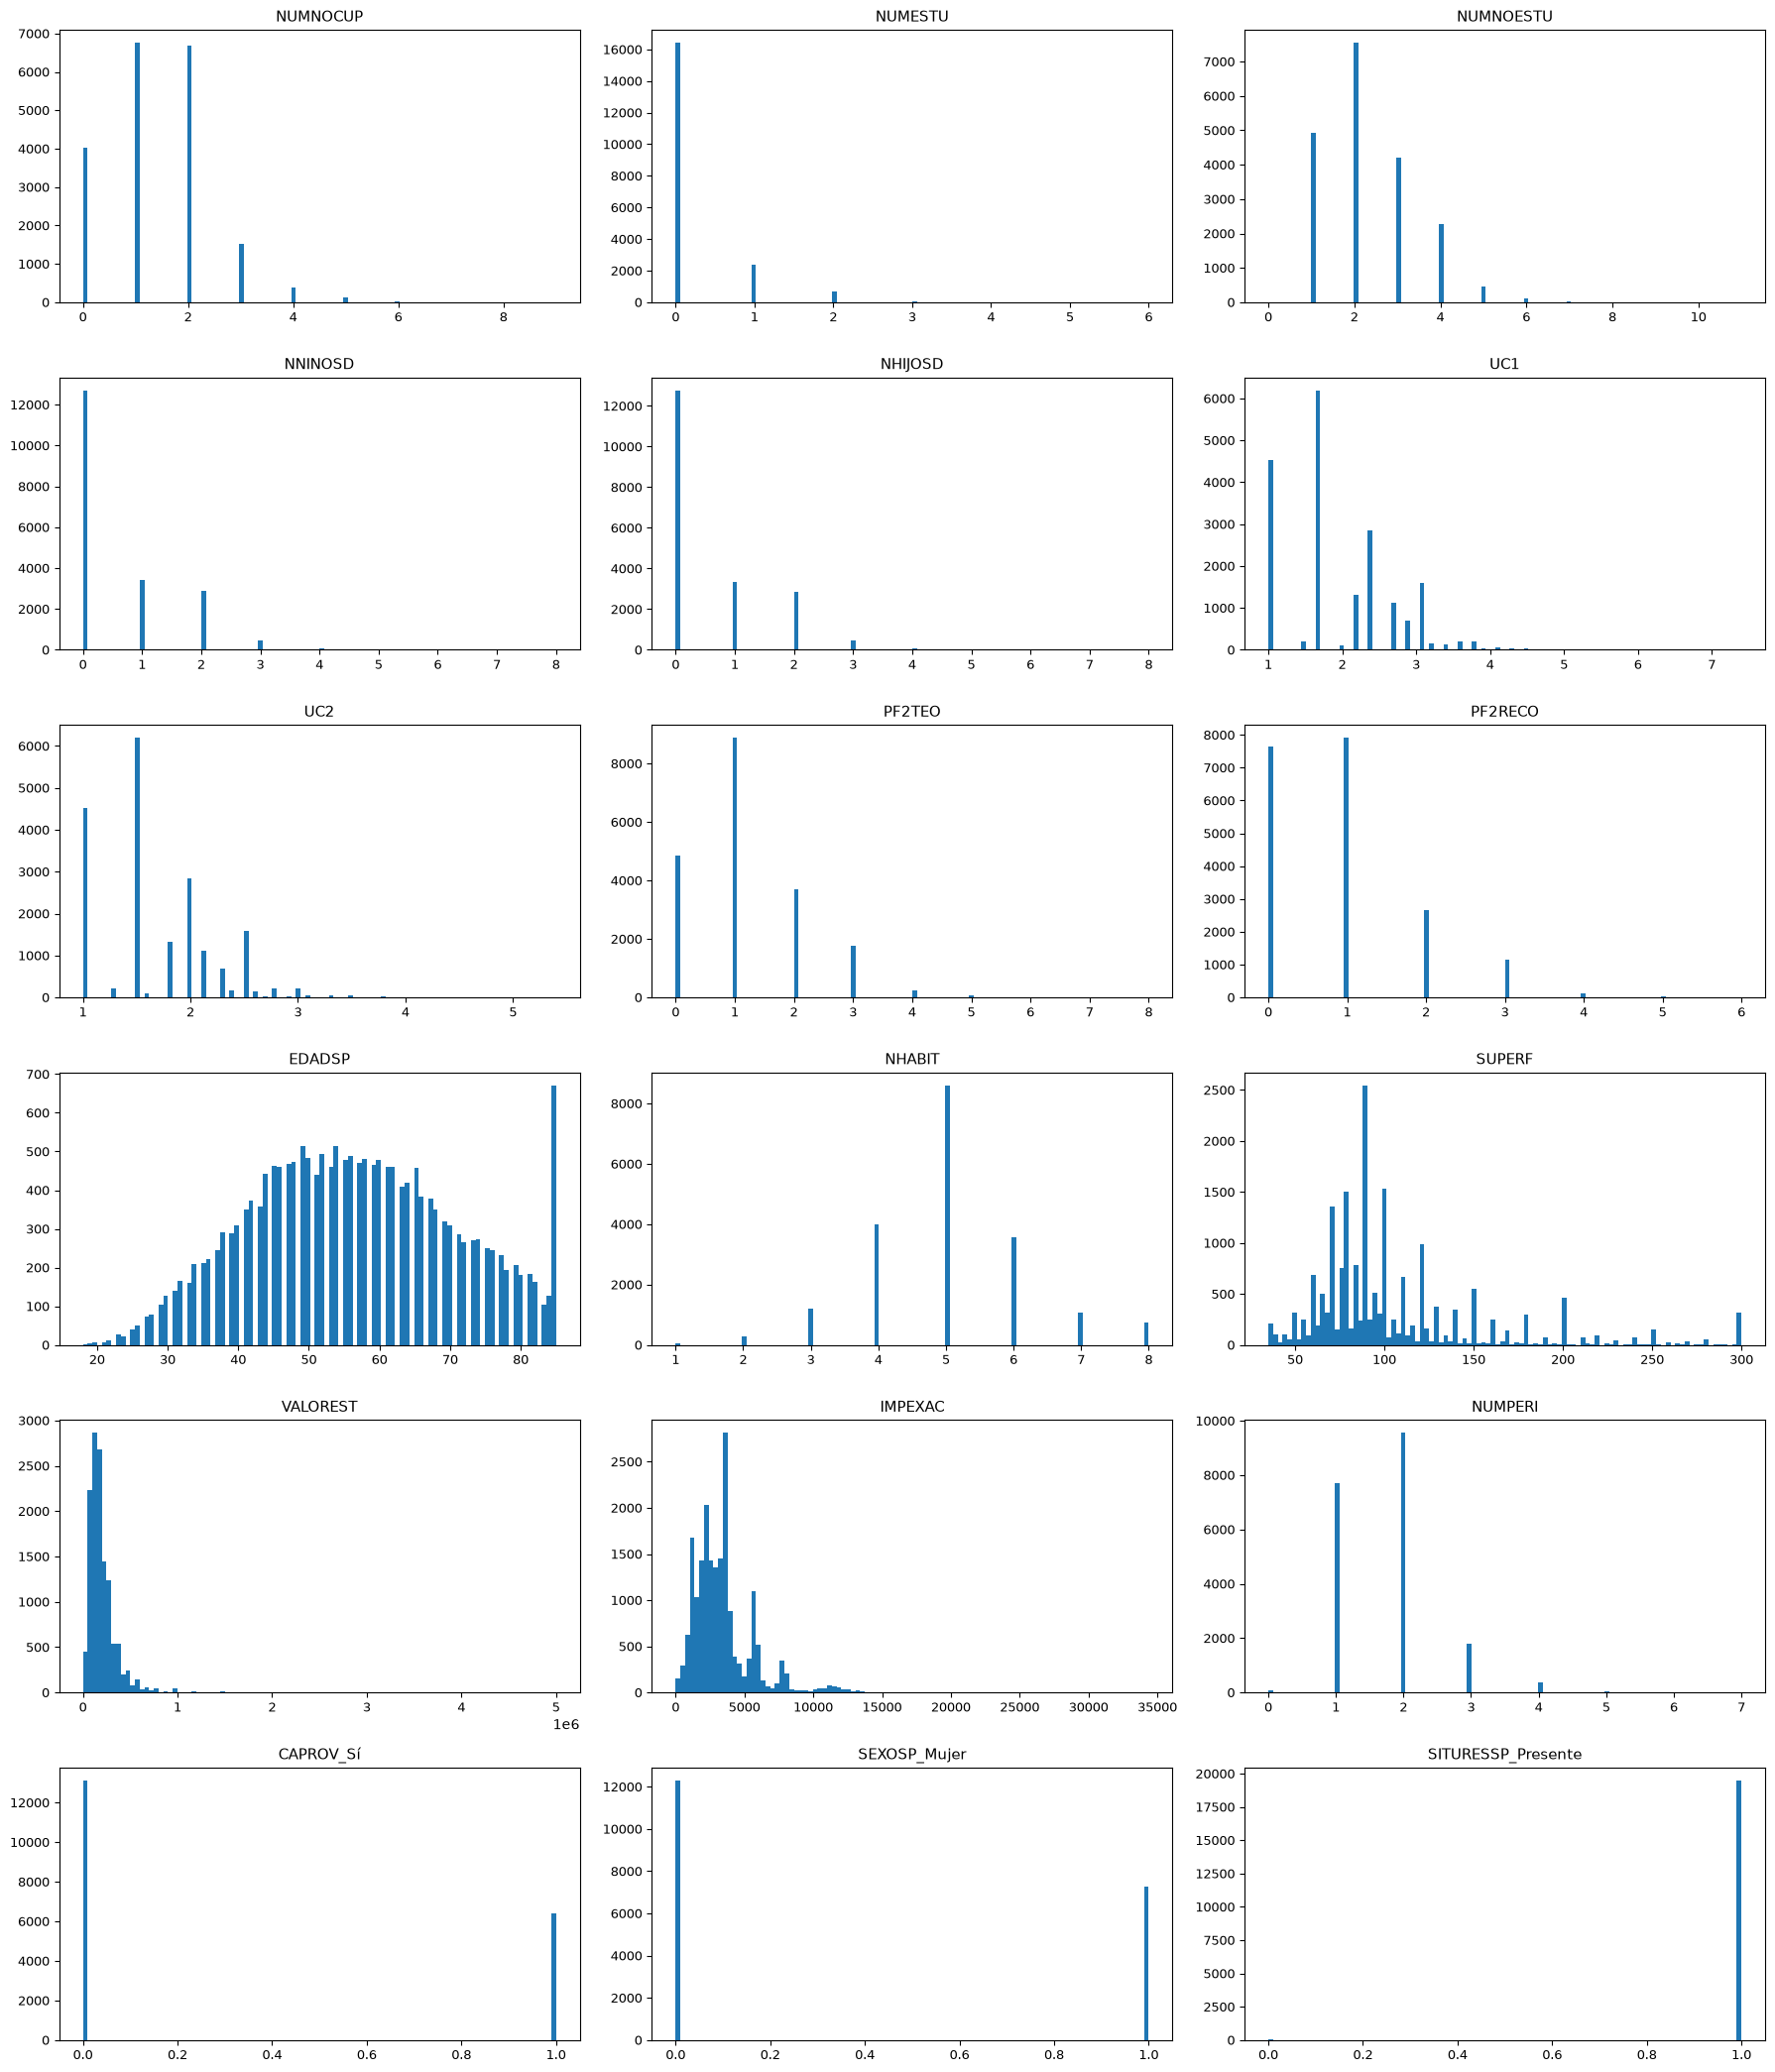

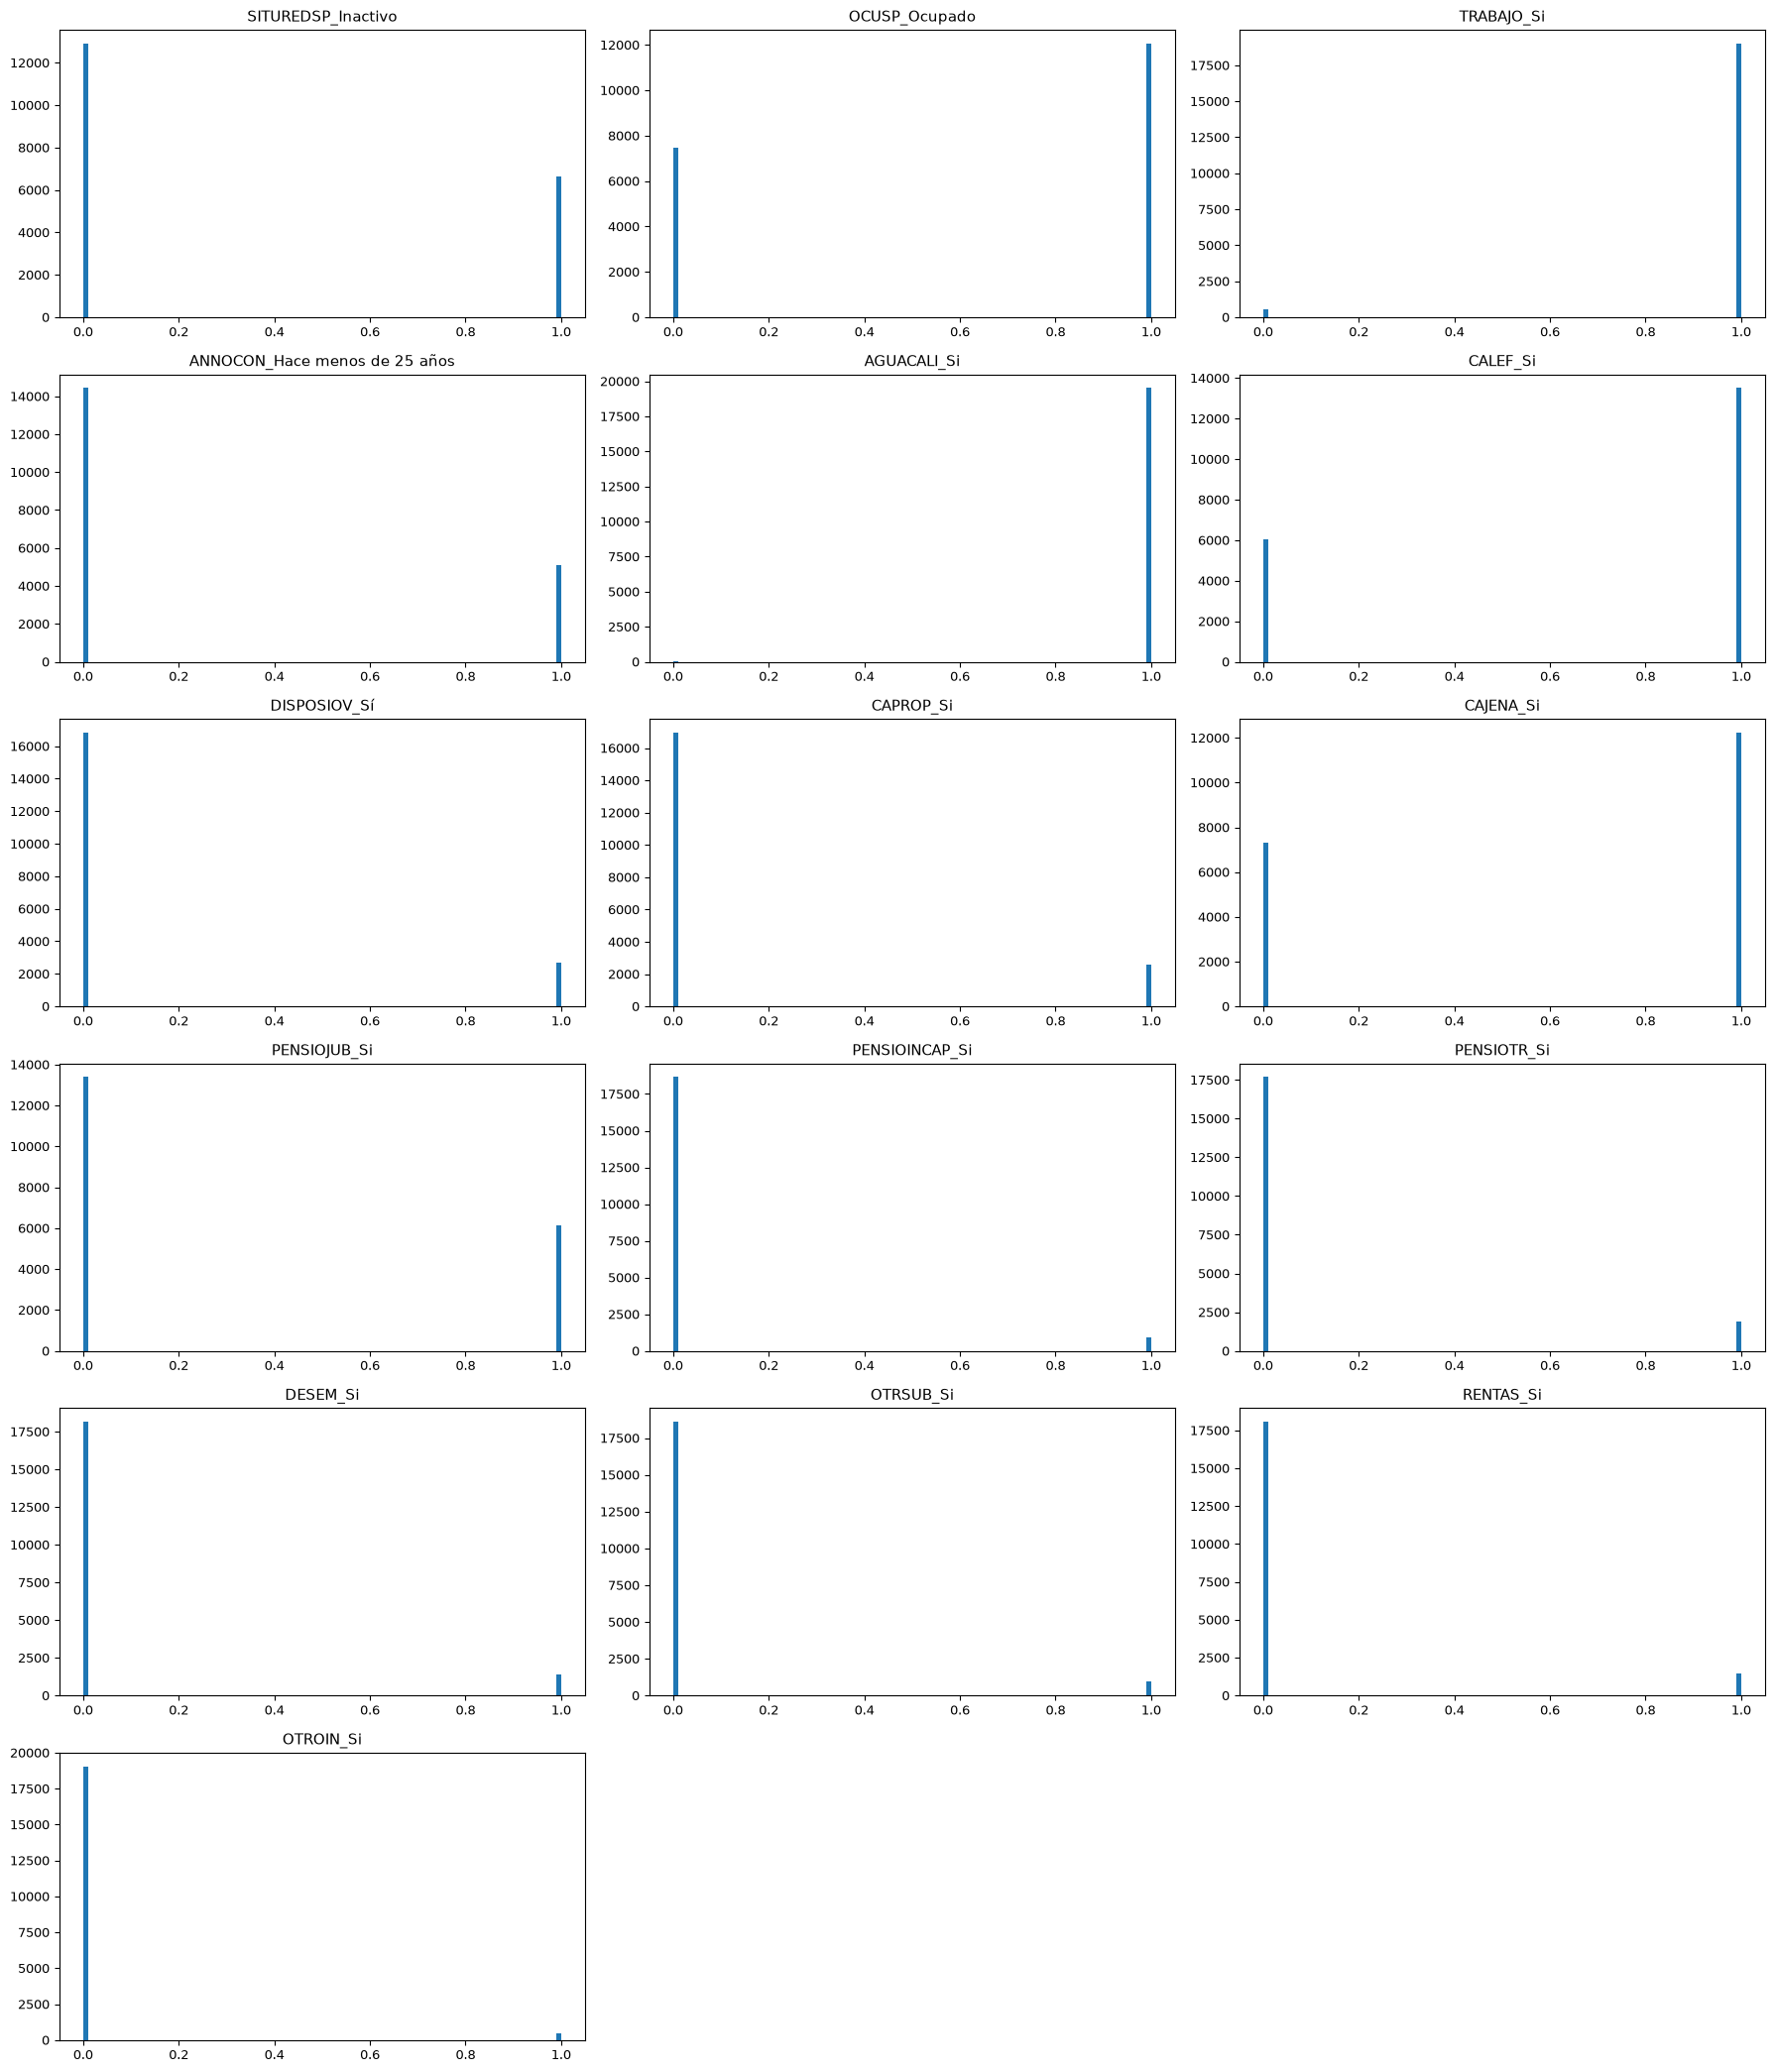

In [4]:
num_cols = df_gasto_energetico_with_bin.select_dtypes(include="number").columns.tolist()
tam_bloque = 18

for inicio in range(0, len(num_cols), tam_bloque):
    bloque = num_cols[inicio : inicio + tam_bloque]
    n_cols = 3
    n_rows = math.ceil(len(bloque) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.5))
    axes = axes.ravel()

    for i, col in enumerate(bloque):
        axes[i].hist(df_gasto_energetico_with_bin[col].dropna(), bins=100)
        axes[i].set_title(col, fontsize=11)
        axes[i].tick_params(axis="both", labelsize=9)

    for j in range(len(bloque), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

In [5]:
# df_correlaciones = pd.DataFrame({"pearson": train_set_with_bin[num_cols].corr(method= "pearson")[target], "spearman" : train_set_with_bin[num_cols].corr(method= "spearman")[target]})
# df_correlaciones

In [6]:
resultados = []

for col in num_cols:
    if col == "GASTO_SUMINISTROS":
        resultados.append({
            "variable": col,
            "pearson": 1.0,
            "p_pearson": 0.0,
            "spearman": 1.0,
            "p_spearman": 0.0
        })
        continue

    # Filtramos pares sin NaN para evitar errores en scipy.stats
    sub = df_gasto_energetico_with_bin[[col, "GASTO_SUMINISTROS"]].dropna()

    if len(sub) > 2 and sub[col].nunique() > 1:
        r_p, p_p = stats.pearsonr(sub[col], sub["GASTO_SUMINISTROS"])
        r_s, p_s = stats.spearmanr(sub[col], sub["GASTO_SUMINISTROS"])
    else:
        r_p, p_p, r_s, p_s = np.nan, np.nan, np.nan, np.nan

    resultados.append({
        "variable": col,
        "pearson": r_p,
        "p_pearson": p_p,
        "spearman": r_s,
        "p_spearman": p_s
    })

df_correlaciones = (
    pd.DataFrame(resultados)
    .set_index("variable")
    .sort_values(by="spearman", key=lambda s: s.abs(), ascending=False)
)

df_correlaciones.round(4)

,pearson,p_pearson,spearman,p_spearman
variable,,,,
GASTO_SUMINISTROS,1.0000,0.0000,1.0000,0.0000
IMPEXAC,0.2559,0.0000,0.3033,0.0000
PF2TEO,0.2532,0.0000,0.3020,0.0000
NMIEM1,0.2535,0.0000,0.3017,0.0000
NMIEM4,0.2546,0.0000,0.3014,0.0000
NMIEM6,0.2544,0.0000,0.2998,0.0000
UC2,0.2520,0.0000,0.2991,0.0000
UC1,0.2482,0.0000,0.2976,0.0000
NMIEMB,0.2365,0.0000,0.2908,0.0000


In [7]:
df_gasto_energetico_with_bin[num_cols].corr(method= "pearson").iloc[1:23, 1:23]

,NMIEMB,NMIEM1,NMIEM2,NMIEM3,NMIEM4,NMIEM5,NMIEM6,NMIEM7,NMIEM8,NMIEM9,...,NMIEM12,NMIEM13,NUMACTI,NUMINACTI,NUMOCUP,NUMNOCUP,NUMESTU,NUMNOESTU,NNINOSD,NHIJOSD
NMIEMB,1.000000,0.837910,0.577730,0.628113,0.802305,0.679754,0.767770,0.312303,0.570054,0.480178,...,-0.153963,-0.060639,0.625194,0.635447,0.566377,0.672601,0.431795,0.908906,0.767571,0.764277
NMIEM1,0.837910,1.000000,0.038583,0.140797,0.967989,0.242993,0.928619,-0.004500,0.166387,0.634884,...,-0.020640,-0.008815,0.586720,0.470256,0.521178,0.521733,0.571966,0.664420,0.435014,0.431250
NMIEM2,0.577730,0.038583,1.000000,0.939384,0.021268,0.881098,0.016918,0.578487,0.794821,-0.070335,...,-0.251008,-0.097835,0.267186,0.460123,0.257517,0.451162,-0.064824,0.670403,0.754714,0.754311
NMIEM3,0.628113,0.140797,0.939384,1.000000,0.039467,0.946837,0.028090,0.518555,0.896504,-0.037355,...,-0.276179,-0.105599,0.287473,0.503231,0.280273,0.490240,-0.030941,0.710590,0.825530,0.825222
NMIEM4,0.802305,0.967989,0.021268,0.039467,1.000000,0.146563,0.964379,0.003247,0.044304,0.645274,...,0.014152,0.003138,0.582313,0.429967,0.512306,0.487644,0.578222,0.622058,0.352391,0.348396
NMIEM5,0.679754,0.242993,0.881098,0.946837,0.146563,1.000000,0.051961,0.470627,0.859393,0.138521,...,-0.299291,-0.112011,0.312698,0.543031,0.302204,0.531544,0.153786,0.682432,0.890145,0.889290
NMIEM6,0.767770,0.928619,0.016918,0.028090,0.964379,0.051961,1.000000,0.014096,0.025427,0.532799,...,0.051822,0.015286,0.578093,0.390836,0.507174,0.451461,0.453584,0.641398,0.267501,0.263762
NMIEM7,0.312303,-0.004500,0.578487,0.518555,0.003247,0.470627,0.014096,1.000000,0.086072,-0.076352,...,-0.145780,-0.057025,0.166257,0.227136,0.153659,0.230906,-0.082609,0.384390,0.391038,0.388451
NMIEM8,0.570054,0.166387,0.794821,0.896504,0.044304,0.859393,0.025427,0.086072,1.000000,-0.003964,...,-0.246266,-0.093495,0.248816,0.468671,0.246954,0.451580,0.006751,0.628803,0.759285,0.760268
NMIEM9,0.480178,0.634884,-0.070335,-0.037355,0.645274,0.138521,0.532799,-0.076352,-0.003964,1.000000,...,-0.228803,-0.073523,0.353921,0.251984,0.305617,0.292749,0.829442,0.148825,0.462962,0.456144


In [8]:
df_gasto_energetico_with_bin[num_cols].corr(method= "spearman").iloc[1:23, 1:23]

,NMIEMB,NMIEM1,NMIEM2,NMIEM3,NMIEM4,NMIEM5,NMIEM6,NMIEM7,NMIEM8,NMIEM9,...,NMIEM12,NMIEM13,NUMACTI,NUMINACTI,NUMOCUP,NUMNOCUP,NUMESTU,NUMNOESTU,NNINOSD,NHIJOSD
NMIEMB,1.000000,0.860767,0.551070,0.599464,0.830746,0.650285,0.801047,0.303236,0.546400,0.462486,...,-0.193340,-0.073528,0.645099,0.586539,0.585763,0.626183,0.421689,0.917017,0.738060,0.735070
NMIEM1,0.860767,1.000000,0.090648,0.186480,0.970739,0.276683,0.937200,0.014969,0.201208,0.574482,...,-0.045052,-0.025271,0.573947,0.457052,0.510661,0.509828,0.521671,0.735559,0.436442,0.432890
NMIEM2,0.551070,0.090648,1.000000,0.923080,0.065751,0.859081,0.053263,0.561362,0.786692,-0.041278,...,-0.289047,-0.108794,0.327671,0.401607,0.309465,0.393169,-0.035109,0.611759,0.738469,0.737800
NMIEM3,0.599464,0.186480,0.923080,1.000000,0.094250,0.932835,0.071686,0.509651,0.896249,0.015138,...,-0.320055,-0.117485,0.354578,0.436482,0.339055,0.425219,0.020878,0.651220,0.808723,0.807896
NMIEM4,0.830746,0.970739,0.065751,0.094250,1.000000,0.192291,0.968737,0.023709,0.094232,0.581524,...,-0.009091,-0.014405,0.562574,0.426749,0.495819,0.483789,0.526220,0.700914,0.365692,0.362063
NMIEM5,0.650285,0.276683,0.859081,0.932835,0.192291,1.000000,0.106566,0.467056,0.841612,0.182341,...,-0.345881,-0.124662,0.383793,0.472222,0.366786,0.462506,0.200017,0.622530,0.875498,0.873941
NMIEM6,0.801047,0.937200,0.053263,0.071686,0.968737,0.106566,1.000000,0.035392,0.063798,0.478300,...,0.026293,-0.003114,0.551829,0.397042,0.484356,0.456335,0.411913,0.712848,0.294467,0.291116
NMIEM7,0.303236,0.014969,0.561362,0.509651,0.023709,0.467056,0.035392,1.000000,0.143097,-0.081163,...,-0.162783,-0.061716,0.195906,0.202738,0.175276,0.205198,-0.087917,0.353660,0.394626,0.392541
NMIEM8,0.546400,0.201208,0.786692,0.896249,0.094232,0.841612,0.063798,0.143097,1.000000,0.053642,...,-0.283822,-0.103351,0.304427,0.420027,0.296099,0.404569,0.061589,0.579338,0.737974,0.738157
NMIEM9,0.462486,0.574482,-0.041278,0.015138,0.581524,0.182341,0.478300,-0.081163,0.053642,1.000000,...,-0.255299,-0.080856,0.352171,0.209839,0.310070,0.246305,0.812448,0.175714,0.480353,0.473016


In [9]:
def evaluar_binarias_mw(df: pd.DataFrame, cols_bin: list[str], target: str = "GASTO_SUMINISTROS") -> pd.DataFrame:
    filas = []
    for col in cols_bin:
        sub = df[[col, target]].dropna()
        vals = sub[col].unique()
        if len(vals) != 2:
            continue
        g0 = sub.loc[sub[col] == vals[0], target]
        g1 = sub.loc[sub[col] == vals[1], target]
        _, p_val = mannwhitneyu(g0, g1, alternative="two-sided")
        filas.append({
            "col": col,
            "n_g0": len(g0),
            "n_g1": len(g1),
            "mediana_g0": g0.median(),
            "mediana_g1": g1.median(),
            "diff_mediana": abs(g1.median() - g0.median()),
            "p_valor": p_val,
        })
    return pd.DataFrame(filas).sort_values("p_valor")

evaluar_binarias_mw(df_gasto_energetico_with_bin, cols_bin_out).round(4)

,col,n_g0,n_g1,mediana_g0,mediana_g1,diff_mediana,p_valor
8,CALEF_Si,13512,6032,1329.0738,1001.6923,327.3815,0.0000
10,CAPROP_Si,16961,2583,1192.3739,1388.0945,195.7206,0.0000
1,SEXOSP_Mujer,12298,7246,1262.2911,1147.2052,115.0859,0.0000
11,CAJENA_Si,12237,7307,1257.1200,1157.1711,99.9489,0.0000
0,CAPROV_Sí,13120,6424,1252.6884,1156.7673,95.9212,0.0000
4,OCUSP_Ocupado,12066,7478,1253.3336,1159.1969,94.1367,0.0000
5,TRABAJO_Si,19023,521,1223.2600,986.0477,237.2123,0.0000
16,OTRSUB_Si,18613,931,1225.2712,1070.9412,154.3299,0.0000
12,PENSIOJUB_Si,13386,6158,1196.2750,1260.7542,64.4792,0.0000
14,PENSIOTR_Si,17677,1867,1225.7705,1116.0000,109.7705,0.0000


In [10]:
# cols_excluidas = [
#     # Bloque del hogar: duplicadas, redundantes o con señal muy débil/nula frente a GASTO_SUMINISTROS
#     "NHIJOSD", "NUMESTU", "NUMNOESTU", "NUMACTI", "NUMINACTI",
#     "NMIEM1", "NMIEM6", "NMIEMSD", "NMIEMHU", "NMIEMIN",
#     "NMIEM2", "NMIEM3", "NMIEM5", "NMIEM7", "NMIEM8",
#     "NMIEM11", "NMIEM12", "NMIEM13", "CALEF", "OCUSP",
#     # Binarias muy desbalanceadas con correlación mínima y poca diferencia entre ellas frente a GASTO_SUMINISTROS
#     "SITURESSP_Presente", "PENSIOINCAP_Si", "OTROIN_Si", "SITURESSP", "PENSIOINCAP", "OTROIN"
# ]

In [11]:
# cols_excluidas = [
#     # Hogar: redundantes con NMIEMB y TIPHOGAR1 (|r| > 0.8-0.99 entre ellas)
#     "NMIEM1", "NMIEM2", "NMIEM3", "NMIEM4", "NMIEM5", "NMIEM6", "NMIEM7", "NMIEM8", "NMIEM9", "NMIEM10", "NMIEM11", "NMIEM12", "NMIEM13",
#     "PF2TEO", "PF2RECO", "UC1", "UC2", "NUMACTI", "NUMINACTI", "NUMOCUP", "NUMNOCUP", "NUMESTU", "NUMNOESTU", "NNINOSD", "NHIJOSD", "NUMPERI",
#     # Versiones derivadas o redundantes de otra variable que ya se mantiene
#     "NUTS1", "TIPHOGAR7", "TIPHOGAR8", "SITSOCI", "OCUPA", "OCUPARED", "FUENPRIN", "SITUACTSP", "SITUREDSP",
#     "ACTESTB", "ACTESTBRED", "CALEF", "AGUACALI", "OCUSP", "SITPROF", "TIPOCONT",
#     # Señal casi nula (eta² < 0.005, |ρ| < 0.05 o p > 0.05)
#     "ESTUDIOSSP", "ESTUDREDSP", "JORNADASP", "CONTRATO", "PERCEPSP", "SECTOR", "PAISNACSP", "PAISPADRESP", "PAISMADRESP", "NACIONASP",
#     "SITURESSP", "PENSIOINCAP", "OTROIN", "DESEM", "PENSIOTR", "RENTAS", "PENSIOJUB", "ANNOCON", "DISPOSIOV", "TRABAJO",
# ]

In [12]:
no_num_multi =  [col for col in no_num if col not in no_num_binary]
no_num_multi

['CCAA',
 'NUTS1',
 'TAMAMU',
 'DENSIDAD',
 'TIPHOGAR1',
 'TIPHOGAR7',
 'TIPHOGAR8',
 'PAISNACSP',
 'NACIONASP',
 'ESTADOCIVILSP',
 'PAISPADRESP',
 'PAISMADRESP',
 'ESTUDIOSSP',
 'ESTUDREDSP',
 'SITUACTSP',
 'JORNADASP',
 'PERCEPSP',
 'OCUPA',
 'OCUPARED',
 'ACTESTB',
 'ACTESTBRED',
 'SITPROF',
 'SECTOR',
 'CONTRATO',
 'TIPOCONT',
 'SITSOCI',
 'SITSOCIRE',
 'REGTEN',
 'TIPOEDIF',
 'ZONARES',
 'TIPOCASA',
 'FUENAGUA',
 'FUENCALE',
 'FUENPRIN',
 'FUENPRINRED']

In [13]:
for col in no_num_multi:

    resumen = (
        df_gasto_energetico.groupby(col)["GASTO_SUMINISTROS"]
        .agg(["count", "mean", "median", "std"])
        .sort_values("mean", ascending=False)
    )

    print(f"\n--- {col} ---")
    print(resumen)


--- CCAA ---
                             count         mean       median         std
CCAA                                                                    
Castilla-La Mancha            1092  1691.710488  1487.999995  972.000933
Cataluña                      1437  1602.401606  1389.174998  879.429258
Madrid, Comunidad de          1747  1581.189920  1407.051892  833.875574
Navarra, Comunidad Foral de    570  1567.022908  1355.240457  959.908936
Balears, Illes                 501  1565.443663  1440.000001  718.310301
Castilla y León               1359  1548.098240  1356.510926  901.182399
Rioja, La                      551  1467.584570  1299.666507  801.037995
Aragón                         947  1446.125418  1232.599994  903.620314
Galicia                       1286  1411.252714  1210.569388  834.528015
Asturias, Principado de        729  1402.329970  1268.268019  677.679434
Murcia, Región de              916  1377.526385  1237.005260  719.006434
Cantabria                      685  1

In [14]:
from scipy.stats import f_oneway, kruskal
import numpy as np
import pandas as pd

resultados = []

for col in no_num_multi:

    grupos = [
        grupo["GASTO_SUMINISTROS"].dropna().values
        for _, grupo in df_gasto_energetico.groupby(col)
        if len(grupo["GASTO_SUMINISTROS"].dropna()) >= 2
    ]

    if len(grupos) >= 2:

        # Unir todas las observaciones
        valores = np.concatenate(grupos)

        # Calcular eta cuadrado
        media_global = valores.mean()

        ss_total = np.sum((valores - media_global) ** 2)

        ss_entre = sum(
            len(g) * (g.mean() - media_global) ** 2
            for g in grupos
        )

        eta2 = ss_entre / ss_total if ss_total > 0 else np.nan

        # Pruebas estadísticas
        anova = f_oneway(*grupos)
        kruskal_test = kruskal(*grupos)

        resultados.append({
            "variable": col,
            "categorias": len(grupos),
            "eta2": eta2,
            "p_anova": anova.pvalue,
            "p_kruskal": kruskal_test.pvalue
        })

# Crear DataFrame y ordenar por tamaño del efecto
resultados_cat = pd.DataFrame(resultados)

resultados_cat = resultados_cat.sort_values(
    "eta2",
    ascending=False
).reset_index(drop=True)

print(resultados_cat)

         variable  categorias      eta2        p_anova      p_kruskal
0        FUENAGUA           6  0.081222   0.000000e+00   0.000000e+00
1       TIPHOGAR1          12  0.074482   0.000000e+00   0.000000e+00
2       TIPHOGAR7           8  0.068099  2.187179e-293   0.000000e+00
3        FUENCALE           6  0.054196  2.037578e-160  4.985224e-146
4            CCAA          19  0.051758  5.085408e-209  8.735386e-245
5        TIPOCASA           3  0.046409  2.276268e-202  6.039296e-147
6   ESTADOCIVILSP           5  0.046313  2.907906e-199  7.477518e-264
7        TIPOEDIF           4  0.042406  3.200826e-183  3.597869e-101
8       TIPHOGAR8           4  0.038426  1.210446e-165  3.254191e-214
9           NUTS1           7  0.028675  1.474774e-119  1.266370e-152
10       FUENPRIN           9  0.021787   1.405109e-87  1.038379e-104
11        SITSOCI          12  0.019355   6.288931e-73   1.457182e-88
12      SITSOCIRE           7  0.018833   5.020448e-75   4.407288e-89
13          OCUPA   

In [15]:
df_gasto_energetico.to_csv("../data/processed/datos_limpios.csv", index=False)